In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('/workspaces/steel_stock_management/data/inventory_df.csv')
df.set_index('fecha')

,material,inventario
fecha,,
2026-05-19,ARMEX DE 15 x 15,551.00
2026-05-19,ARMEX DE 15 x 20,9.00
2026-05-19,"VARILLA CORRUGADA 3/8""",1148.00
2026-05-19,"VARILLA CORRUGADA 1/2""",511.00
2026-05-19,ALAMBRE RECOCIDO,1924.63
...,...,...
2026-07-01,ALAMBRON,1219.50
2026-07-01,MALLA ELECTROSOLDADA 6-6-10/10,269.30
2026-07-01,"CLAVO PARA MADERA DE 2 1/2""",94.20


In [15]:
materials_df = pd.read_csv('/workspaces/steel_stock_management/data/mat_dict.csv')
mat_dict = materials_df.set_index("material").to_dict(orient="index")

In [16]:
df = df.sort_values(["material","fecha"])

df["daily_change"] = (
    df.groupby("material")["inventario"]
      .diff()
)

df["consumo"] = -df["daily_change"]

df.loc[df["consumo"] < 0, "consumo"] = 0

df.groupby("material")["consumo"].describe()

,count,mean,std,min,25%,50%,75%,max
material,,,,,,,,
ALAMBRE RECOCIDO,36.0,59.777778,87.147858,0.0,3.50,20.5,100.00,445.0
ALAMBRON,36.0,55.388889,99.407467,-0.0,-0.00,0.0,100.00,430.0
ARMEX DE 15 x 15,36.0,8.111111,9.970751,-0.0,1.00,3.5,13.25,43.0
ARMEX DE 15 x 20,36.0,16.972222,17.020133,0.0,1.50,10.0,30.50,60.0
"CLAVO P/CONCRETO 2 1/2"" GALV 1 KG",36.0,11.055556,23.042748,-0.0,0.75,1.5,9.50,97.0
"CLAVO PARA MADERA DE 2 1/2""",36.0,11.944444,17.333608,-0.0,0.00,2.5,25.00,75.0
"CLAVO PARA MADERA DE 4""",36.0,4.861111,17.571329,-0.0,-0.00,-0.0,0.00,100.0
MALLA ELECTROSOLDADA 6-6-10/10,36.0,163.650000,174.872970,-0.0,23.25,104.5,261.25,712.0
"VARILLA CORRUGADA 1/2""",36.0,14.777778,22.544066,-0.0,-0.00,1.0,21.75,84.0


In [17]:
sns.set_theme(style="whitegrid", palette="deep")

def plot_material_subplots(
    grouped,
    graph_type,
    x="fecha",
    y="consumo",
    figsize=(18, 24)
):
    materials = list(grouped.groups.keys())

    fig, axes = plt.subplots(5, 2, figsize=figsize, sharex=False)
    axes = axes.flatten()

    for i, material in enumerate(materials):
        ax = axes[i]
        data = grouped.get_group(material).copy()

        if graph_type == "line":
            sns.lineplot(data=data, x=x, y=y, ax=ax, marker="o")
            ax.tick_params(axis='x', rotation=90, length=0.5)

        elif graph_type == "bar":
            sns.barplot(data=data, x=x, y=y, ax=ax)
            ax.tick_params(axis='x', rotation=90, length=0.5)

        elif graph_type == "scatter":
            sns.scatterplot(data=data, x=x, y=y, ax=ax)
            ax.tick_params(axis='x', rotation=90, length=0.5)

        elif graph_type == "hist":
            sns.histplot(data=data, x=y, ax=ax, kde=True)
            ax.tick_params(axis='x', rotation=90, length=0.5)

        elif graph_type == "box":
            sns.boxplot(data=data, 
                        x=y, 
                        ax=ax,
                        medianprops={"color": "r", "linewidth": 2},
                        boxprops={"facecolor": (.3, .5, .7, .5)},
                        width=0.2)

        ax.set_title(material.upper())
        

    # Remove empty subplots
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()

    fig.savefig(
    f"/workspaces/steel_stock_management/pictures/{graph_type.upper()}plot.png",
    dpi=300,
    bbox_inches="tight"
)
    plt.show()

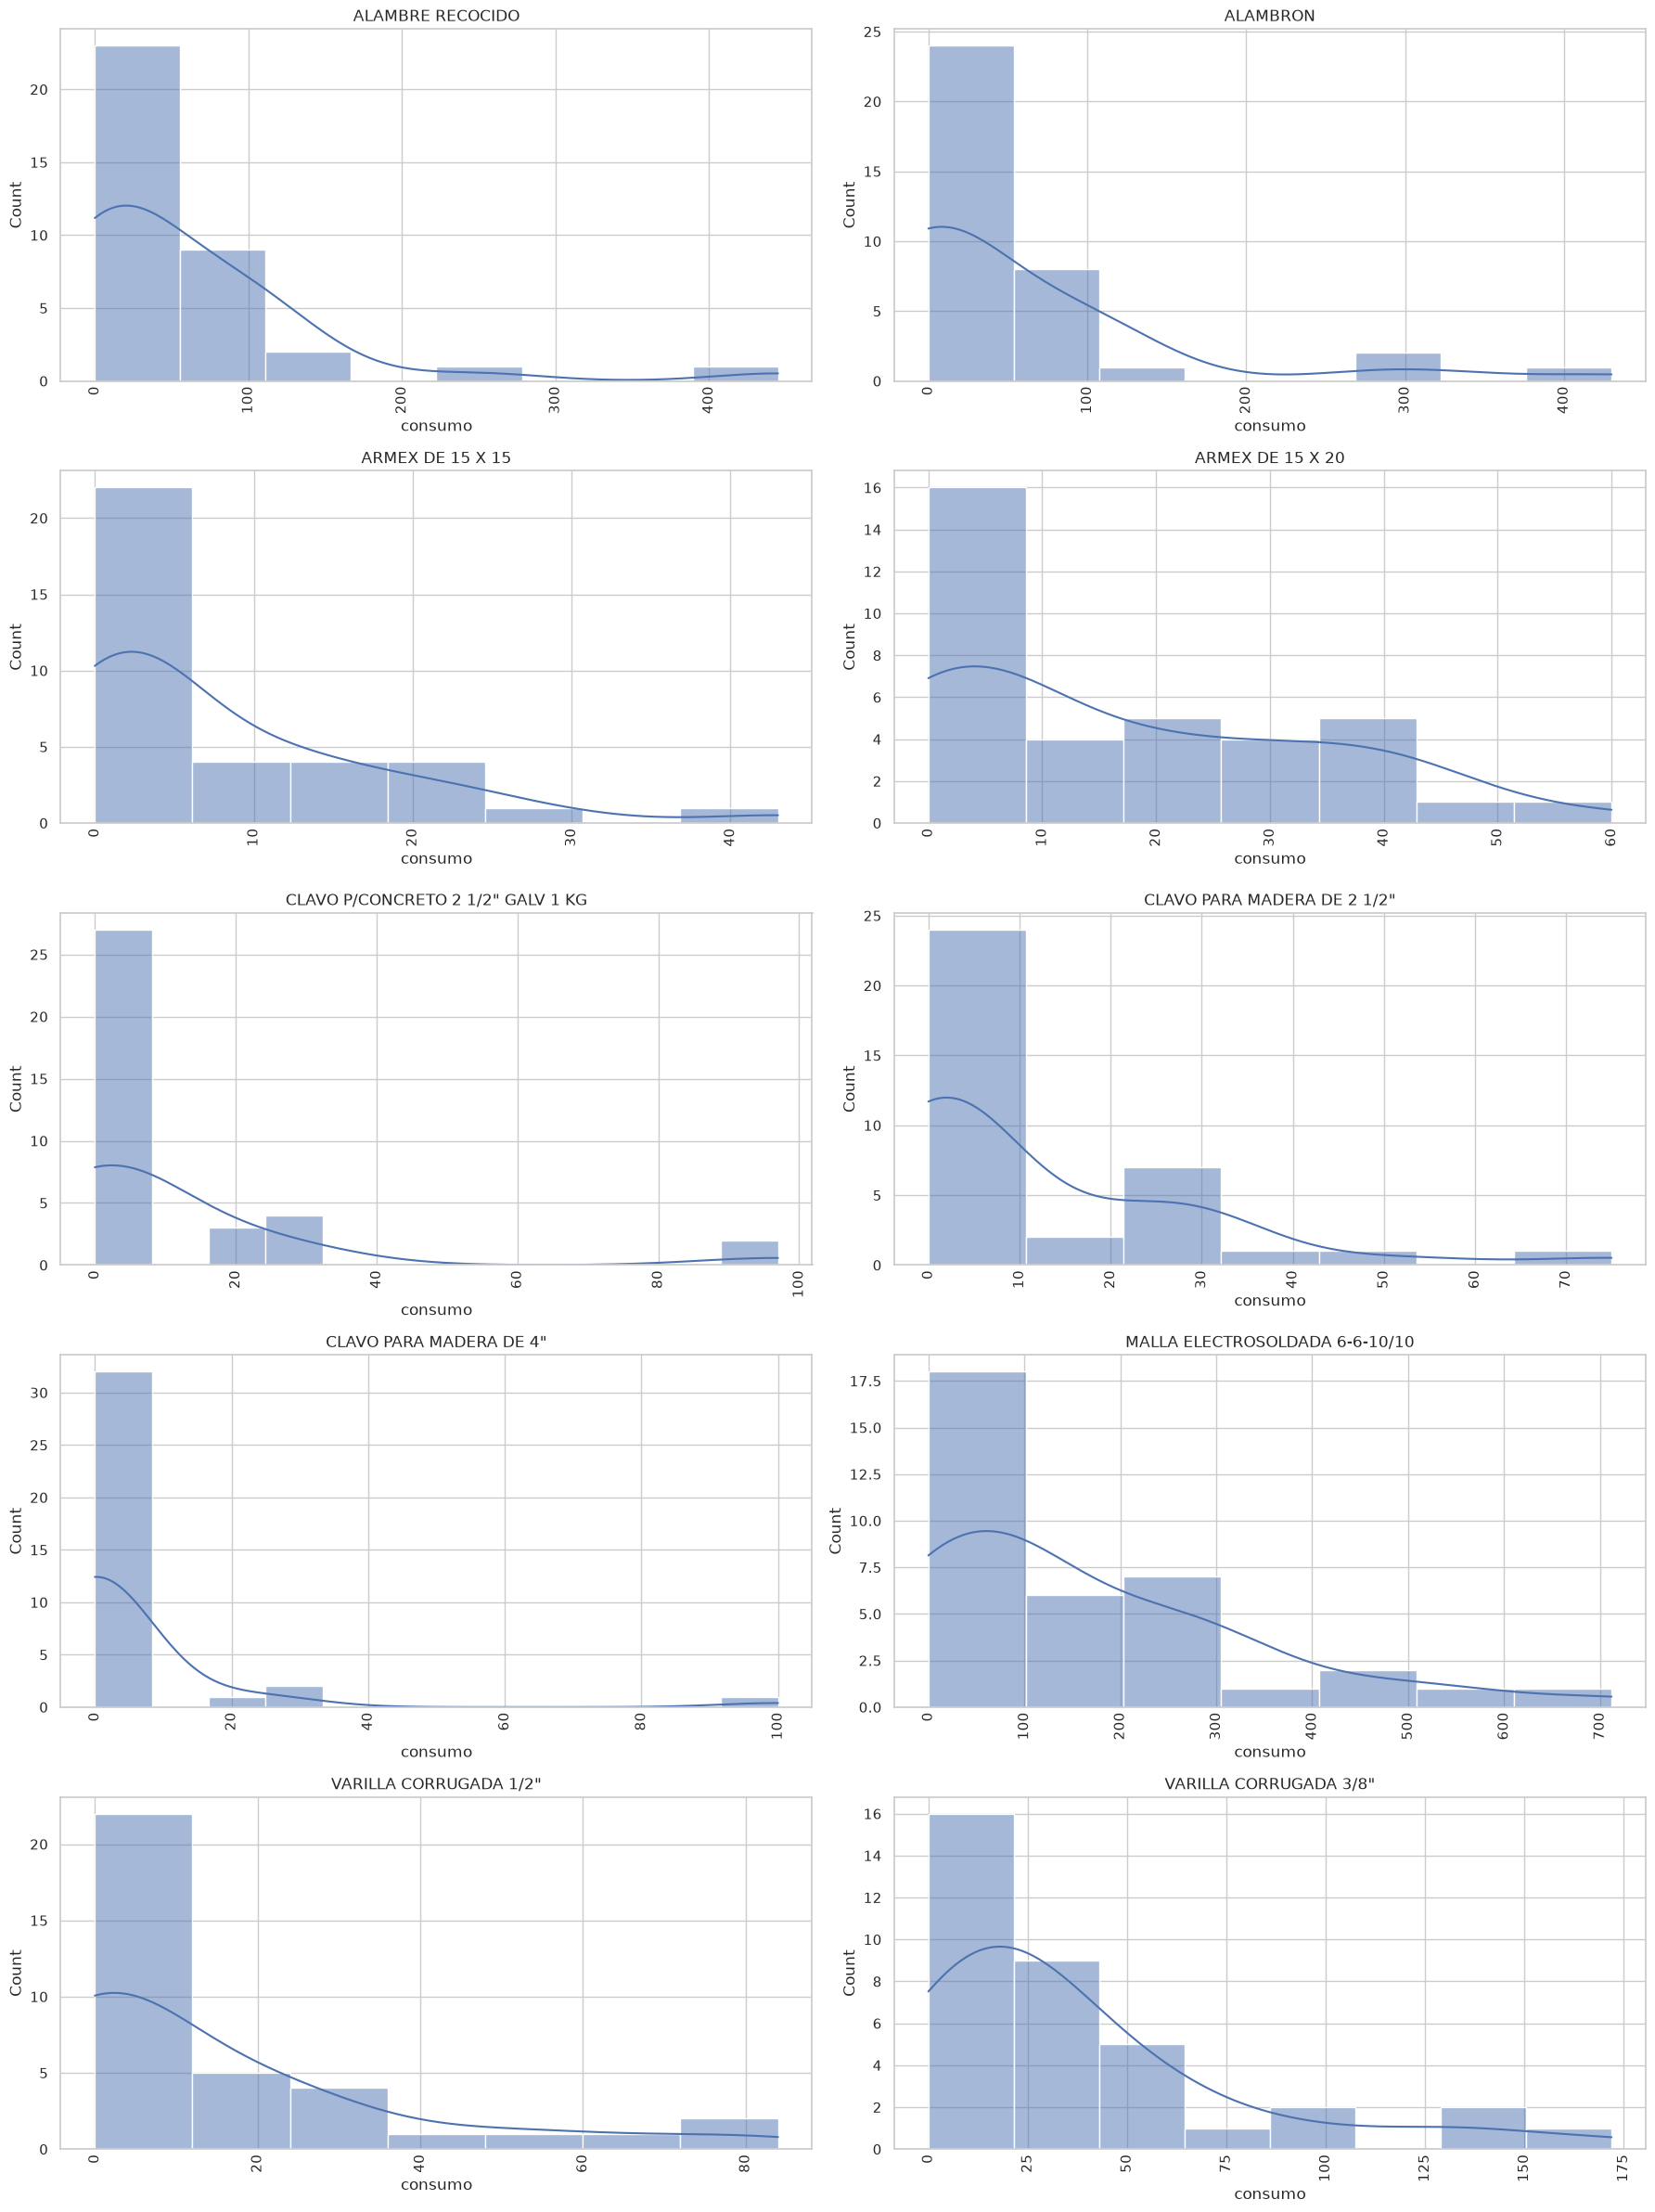

In [18]:
plot_material_subplots(df.groupby('material'), graph_type='hist')

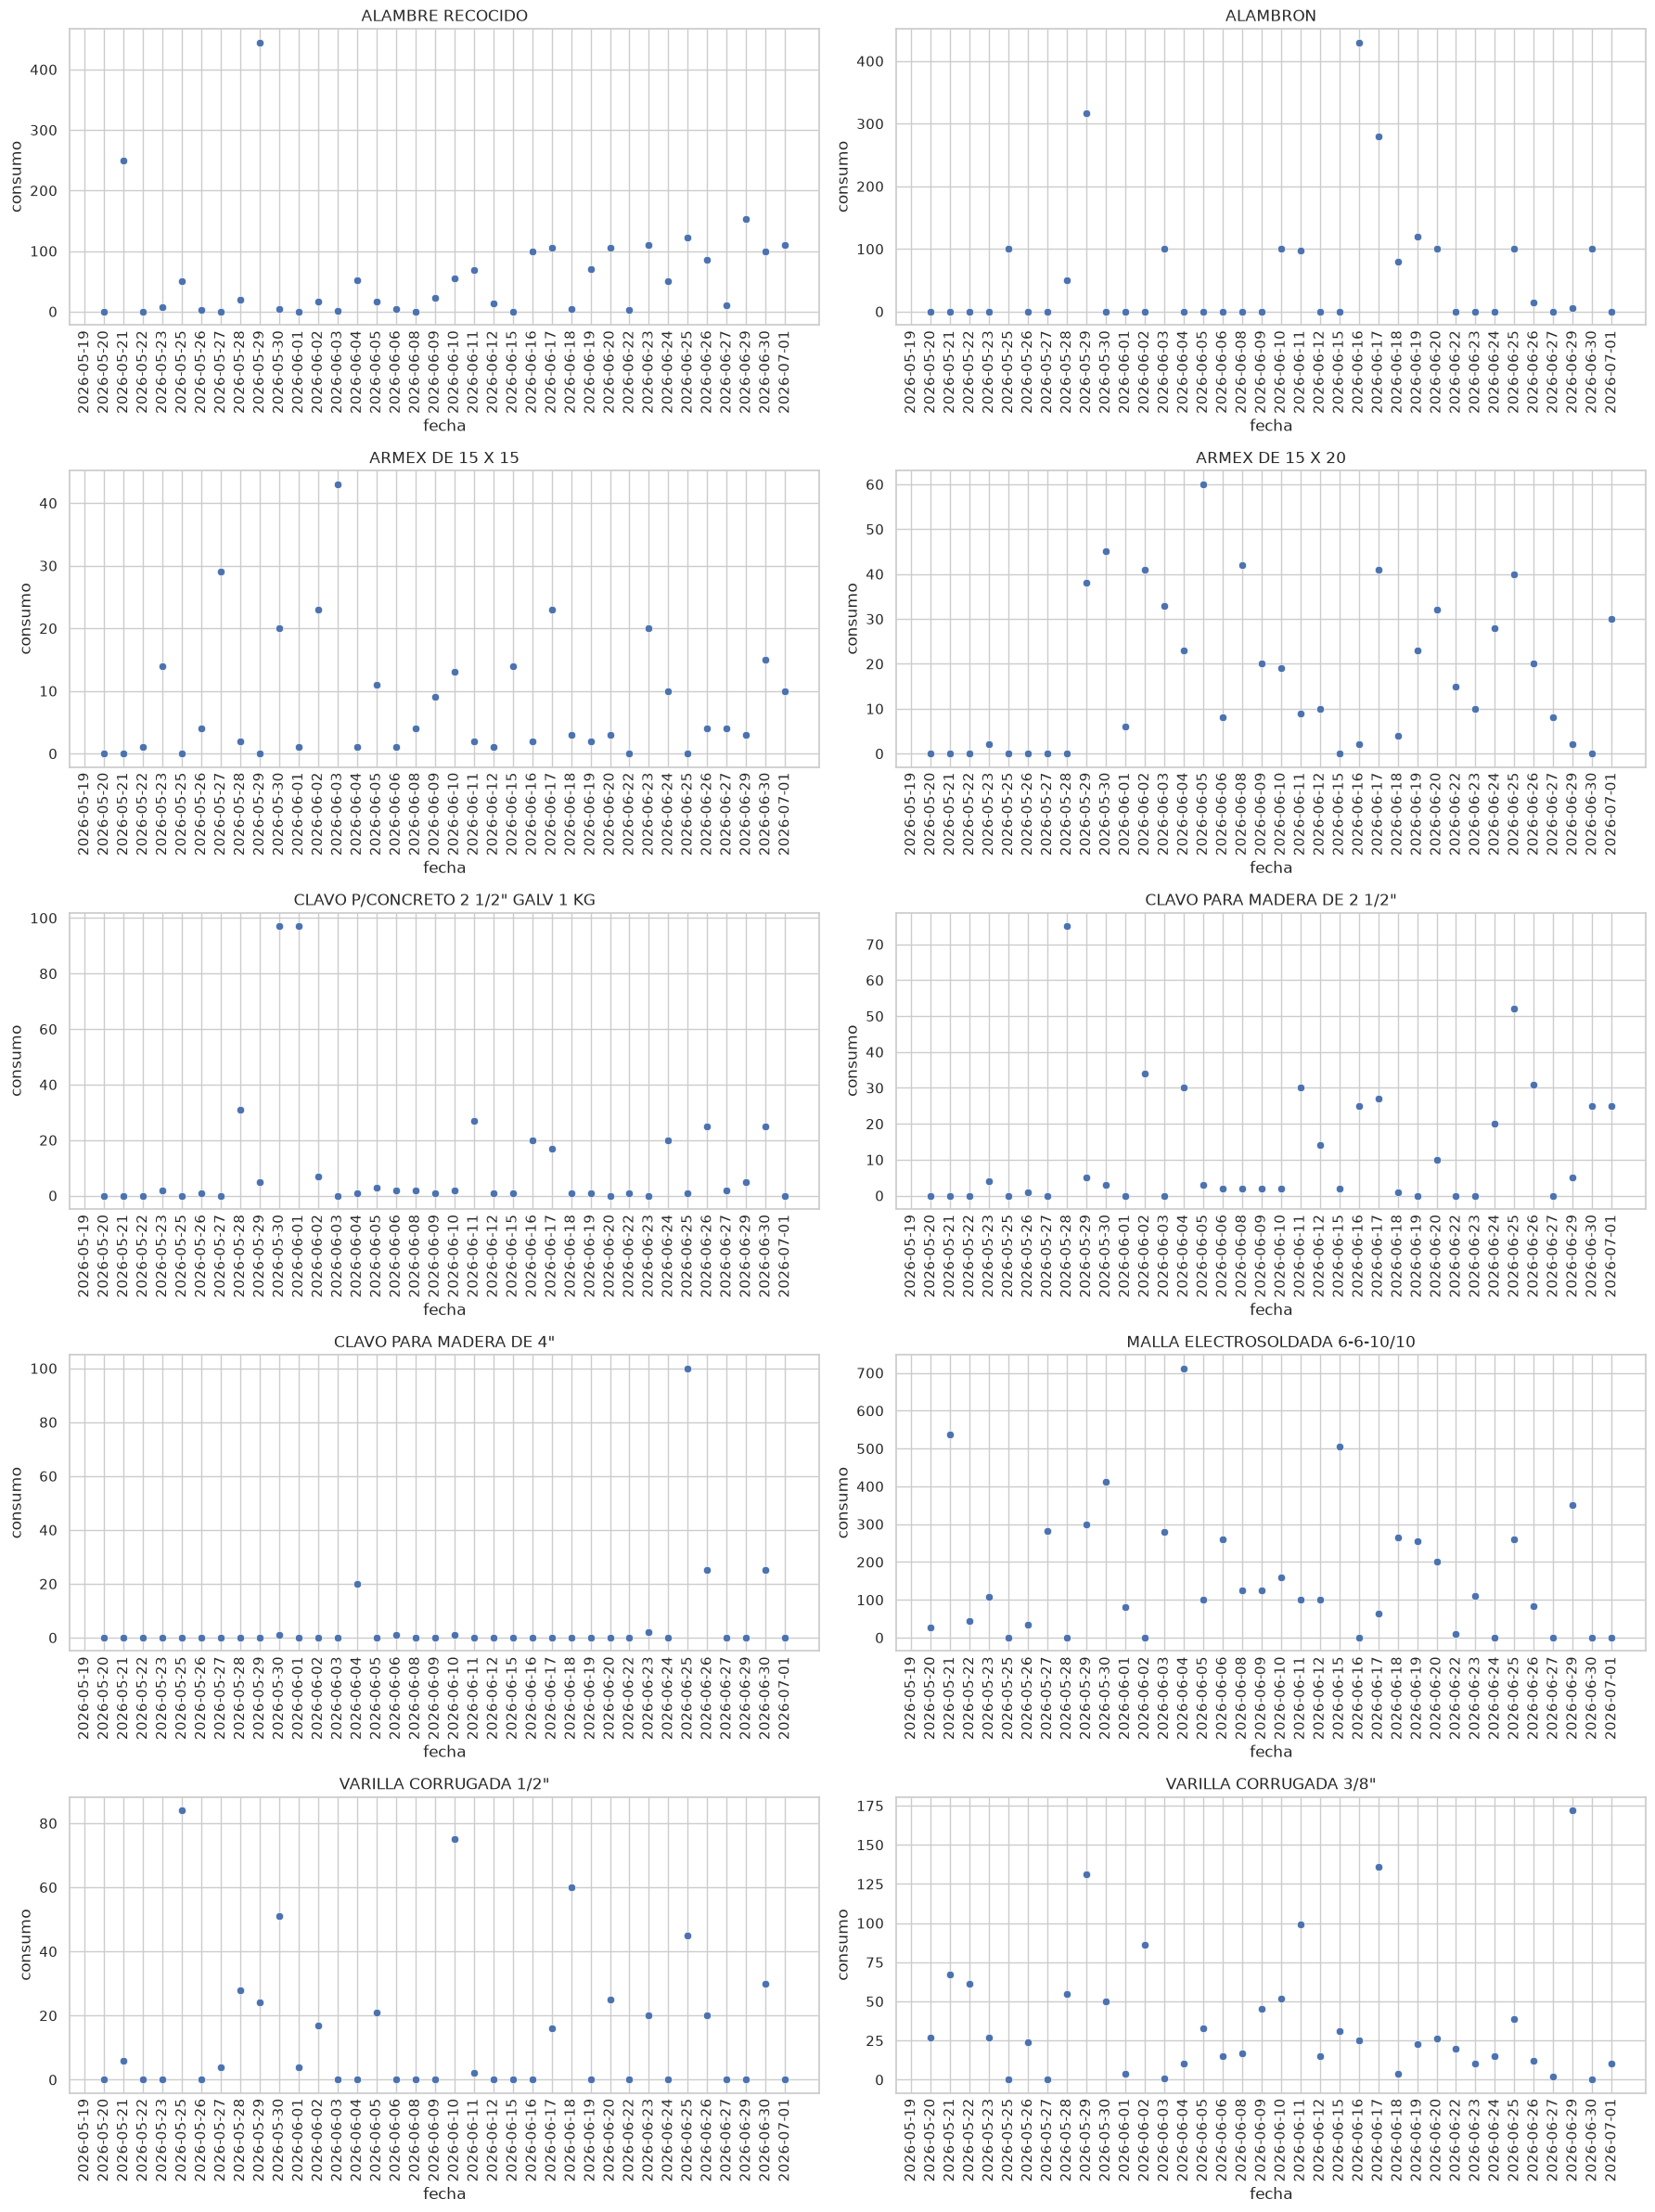

In [19]:
plot_material_subplots(df.groupby('material'), graph_type='scatter')

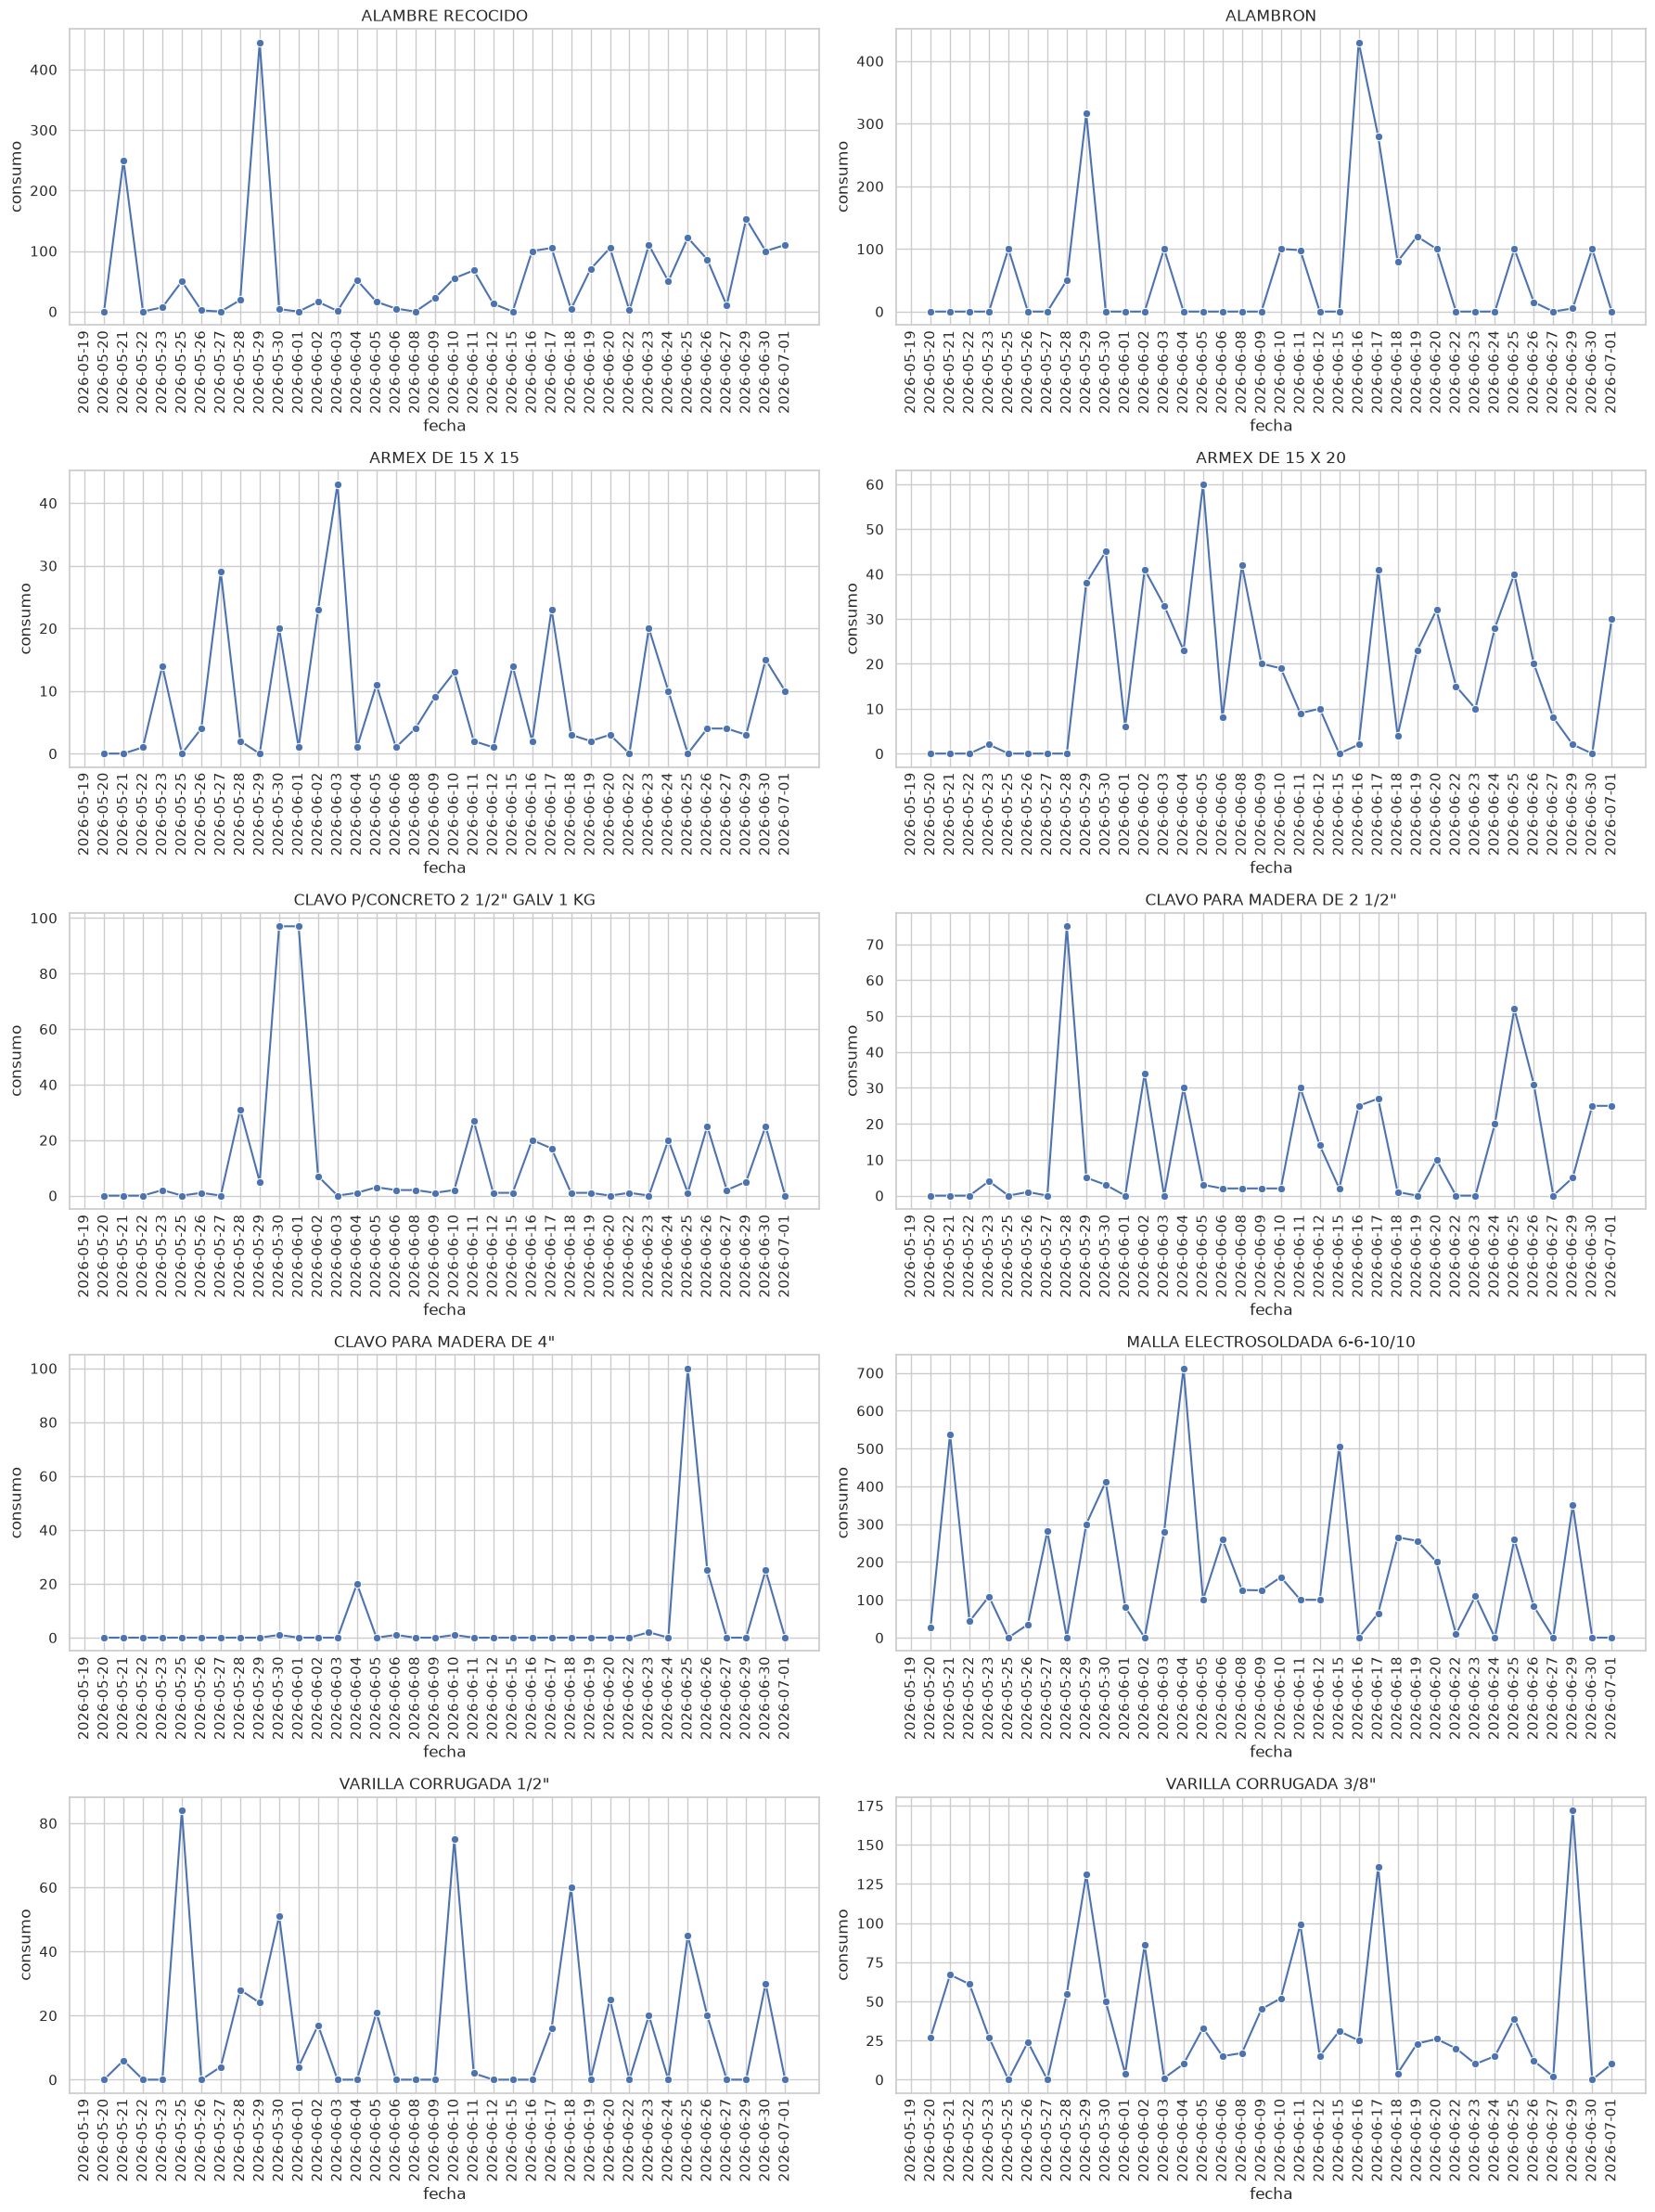

In [20]:
plot_material_subplots(df.groupby('material'), graph_type='line')

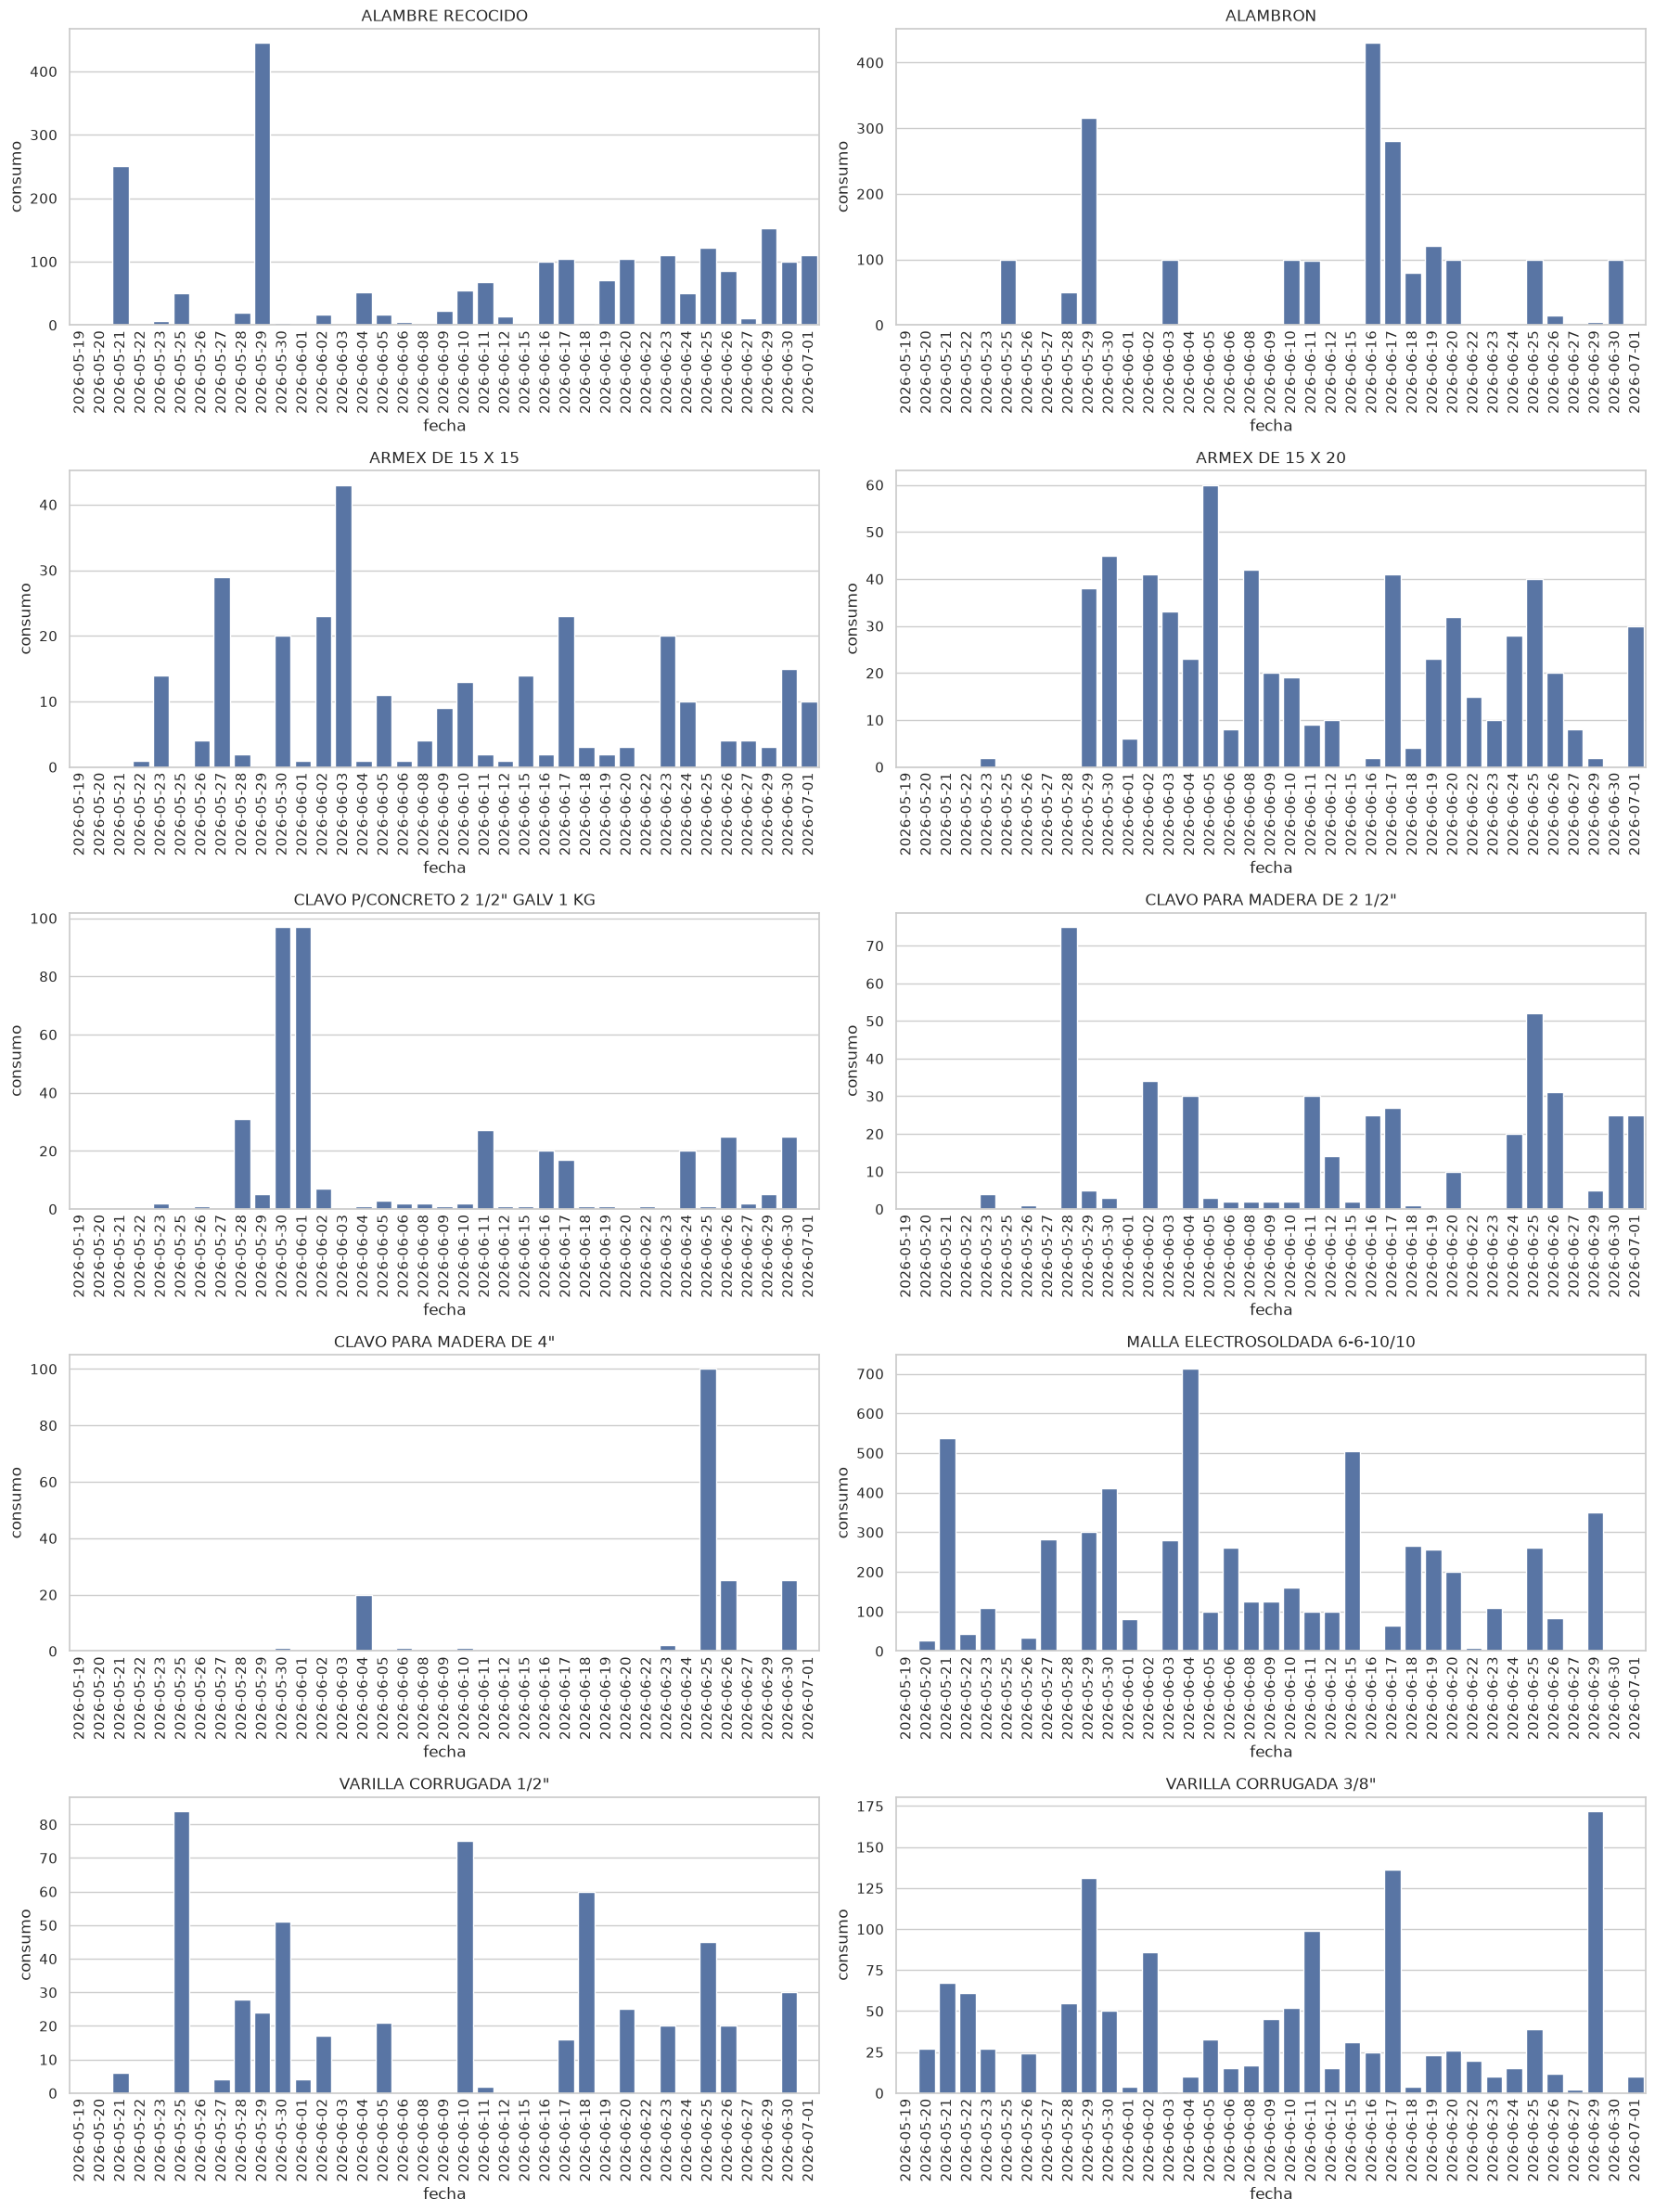

In [21]:
plot_material_subplots(df.groupby('material'), graph_type='bar')

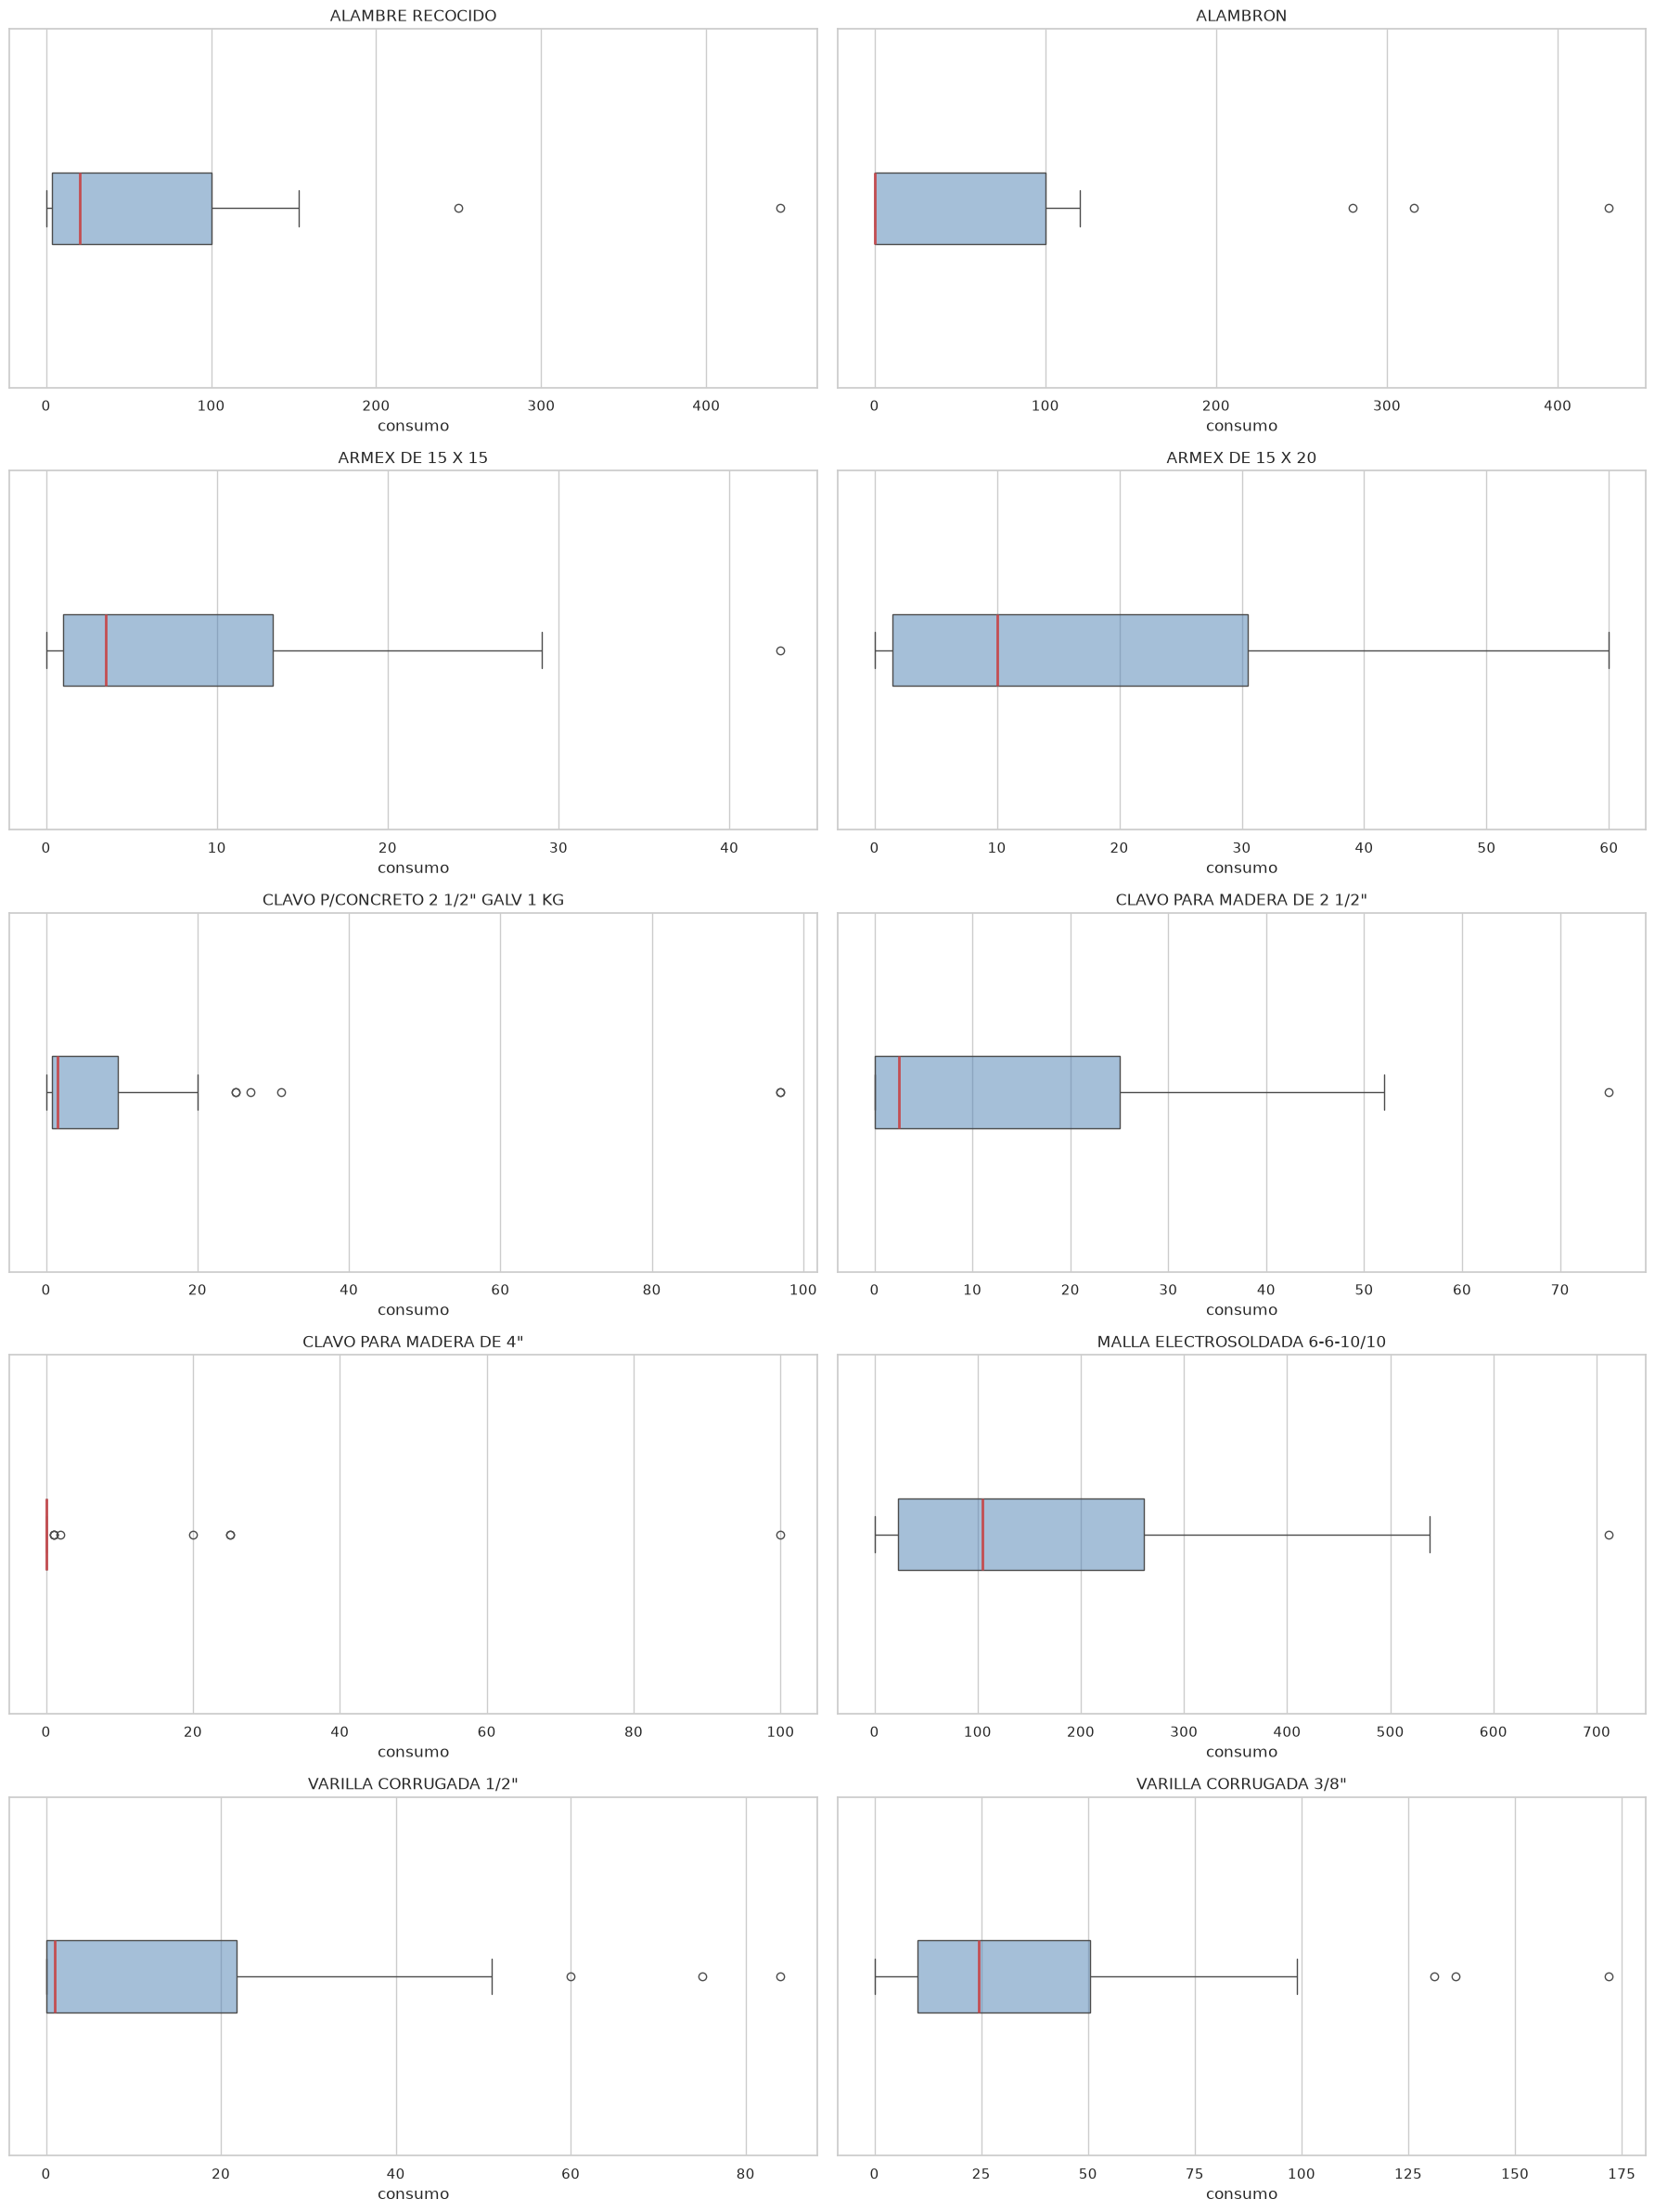

In [22]:
plot_material_subplots(df.groupby('material'), graph_type='box')

In [23]:
cons_mat = df.groupby("material")["consumo"].agg(
    promedio="mean",
    std="std",
    mediana="median",
    max="max",
    min="min",
    consumo_total="sum",
    dias="count"
)

cons_mat["cv %"] = round((
    cons_mat["std"] /
    cons_mat["promedio"]
) * 100, 2)

cons_mat = cons_mat.sort_values("cv %", ascending=False)

cons_mat

,promedio,std,mediana,max,min,consumo_total,dias,cv %
material,,,,,,,,
"CLAVO PARA MADERA DE 4""",4.861111,17.571329,-0.0,100.0,-0.0,175.0,36,361.47
"CLAVO P/CONCRETO 2 1/2"" GALV 1 KG",11.055556,23.042748,1.5,97.0,-0.0,398.0,36,208.43
ALAMBRON,55.388889,99.407467,-0.0,430.0,-0.0,1994.0,36,179.47
"VARILLA CORRUGADA 1/2""",14.777778,22.544066,1.0,84.0,-0.0,532.0,36,152.55
ALAMBRE RECOCIDO,59.777778,87.147858,20.5,445.0,-0.0,2152.0,36,145.79
"CLAVO PARA MADERA DE 2 1/2""",11.944444,17.333608,2.5,75.0,-0.0,430.0,36,145.12
ARMEX DE 15 x 15,8.111111,9.970751,3.5,43.0,-0.0,292.0,36,122.93
"VARILLA CORRUGADA 3/8""",37.333333,41.406004,24.5,172.0,-0.0,1344.0,36,110.91
MALLA ELECTROSOLDADA 6-6-10/10,163.650000,174.872970,104.5,712.0,-0.0,5891.4,36,106.86


In [ ]:
summary = (
    df.groupby("material")
      .agg(
          mean=("consumption", "mean"),
          std=("consumption", "std"),
          median=("consumption", "median"),
          minimum=("consumption", "min"),
          maximum=("consumption", "max"),
          total=("consumption", "sum"),
          days=("consumption", "count")
      )
)

summary["cv"] = summary["std"] / summary["mean"]

summary["%_dias_sin_demanda"] = (
    (df["consumption"] == 0)
    .groupby(df["material"])
    .mean() * 100
)

summary["%_dias_usados"] = (
    (df["consumption"] > 0)
    .groupby(df["material"])
    .mean() * 100
)

summary["prom_consumo_p"] = (
    df[df["consumption"] > 0]
      .groupby("material")["consumption"]
      .mean()
)

summary = summary.sort_values("cv", ascending=False)

summary

,mean,std,median,minimum,maximum,total,days,cv,%_dias_sin_demanda,%_dias_usados,prom_consumo_p
material,,,,,,,,,,,
"CLAVO PARA MADERA DE 4""",4.411765,17.727085,-0.0,-0.0,100.0,150.0,34,4.018139,77.142857,20.000000,21.428571
"CLAVO P/CONCRETO 2 1/2"" GALV 1 KG",10.970588,23.527528,1.5,-0.0,97.0,373.0,34,2.144600,22.857143,74.285714,14.346154
"VARILLA CORRUGADA 1/2""",19.294118,35.368647,2.0,-0.0,172.0,656.0,34,1.833131,45.714286,51.428571,36.444444
ALAMBRON,55.705882,101.623646,0.0,-0.0,430.0,1894.0,34,1.824289,57.142857,40.000000,135.285714
"CLAVO PARA MADERA DE 2 1/2""",11.176471,17.542106,2.0,-0.0,75.0,380.0,34,1.569557,31.428571,65.714286,16.521739
ALAMBRE RECOCIDO,57.117647,89.007240,17.5,-0.0,445.0,1942.0,34,1.558314,17.142857,80.000000,69.357143
ARMEX DE 15 x 15,7.852941,10.189514,3.0,-0.0,43.0,267.0,34,1.297541,17.142857,80.000000,9.535714
"VARILLA CORRUGADA 3/8""",38.264706,40.443233,25.5,-0.0,153.0,1301.0,34,1.056933,11.428571,85.714286,43.366667
MALLA ELECTROSOLDADA 6-6-10/10,173.276471,175.257910,109.5,-0.0,712.0,5891.4,34,1.011435,17.142857,80.000000,210.407143


# SUPPLIER ANALYSIS


NameError: name 'pd' is not defined